# 1. Meet the data

Start here. We will look at the features and groups before fitting an age model.


The GMV values were already normalized by total intracranial volume (TIV).
We keep these original values in Excel. Z-scoring happens here, in Python.

Data source: *Brain clocks chart genetic risk, staging, mechanisms, and multimodal phenotypes in Down syndrome and Alzheimer's disease*, Nature Aging 

The DS participants are a subset of the Barcelona cohort, not the full study sample.

This tutorial illustrates the workflow; it is not a replication of the paper's full analysis.

## What are the features?

Each row is a participant record. Each GMV feature is a TIV-normalized volume from one AAL region.
We use 90 cerebral regions, including subcortical structures. The cerebellar regions are excluded.

CN = cognitively normal controls. AD = Alzheimer's disease. aDS = asymptomatic DS.
pDS = prodromal DS. dDS = DS with dementia.

Later, a linear support vector regression model (SVR) will learn to predict age from these features using CN participants only.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import nibabel as nib
from nilearn import plotting

ROOT = Path.cwd()
DATA = ROOT / "brain_age_data.xlsx"

GROUPS = ["CN", "AD", "aDS", "pDS", "dDS"]
COLORS = {"CN": "#7CAE68", "AD": "#9464A8", "aDS": "#D8C4A5",
          "pDS": "#BC965D", "dDS": "#C6A130"}
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Aptos", "DejaVu Sans"],
                     "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#2F343B", "text.color": "#2F343B",
                     "axes.titlecolor": "#0B2A5B", "figure.dpi": 110})
raw = pd.read_excel(DATA, sheet_name="Participants")
rois = [c for c in raw.columns if c.startswith("G_")]


## Check the table

The table keeps the original values. Here we inspect them before making an analysis copy.

In [2]:
print("Source rows:", len(raw))
print("Repeated participant records:", raw["Row_ID"].duplicated().sum())
print("Nonpositive GMV cells:", (raw[rois] <= 0).sum().sum())
print("Missing ages:", raw["Age"].isna().sum())

# Keep the first record in source order for the one repeated participant.
df = raw.drop_duplicates("Row_ID", keep="first").copy() # ciao duplicated IDs
df = df.loc[df["Age"].notna() & (df["Age"] > 0)].reset_index(drop=True) # you can't have negative ages
df[rois] = df[rois].mask(df[rois] <= 0) # goodbye negative GMV values
df["Group"] = pd.Categorical(df["Group"], categories=GROUPS, ordered=True) # we only have 5 groups
display(df.groupby("Group", observed=True)["Age"].agg(["size", "min", "median", "max"]))


Source rows: 6909
Repeated participant records: 0
Nonpositive GMV cells: 30
Missing ages: 0


,size,min,median,max
Group,,,,
CN,4715,18.000000,62.000000,100.000000
AD,2032,40.000000,73.000000,98.000000
aDS,92,18.564384,39.860274,63.567123
pDS,27,41.378082,50.287671,59.353425
dDS,43,44.063014,53.243836,62.317808


Group
CN     4715
AD     2032
aDS      92
pDS      27
dDS      43
Name: Participants, dtype: int64

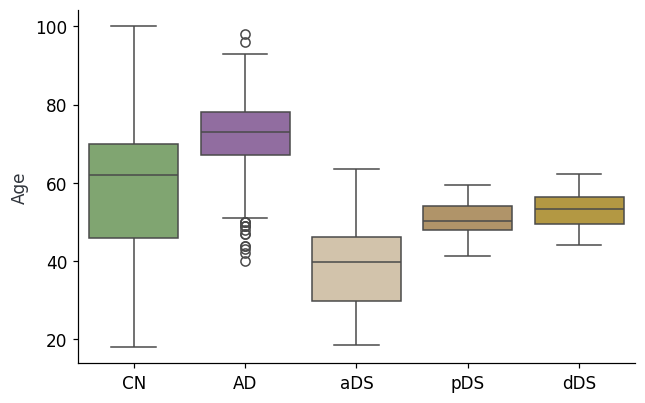

In [3]:
display(df.groupby("Group", observed=True).size().rename("Participants"))
fig, ax = plt.subplots(figsize=(6, 3.8))
sns.boxplot(data=df, x="Group", y="Age", hue="Group", order=GROUPS,
            palette=COLORS, dodge=False, legend=False, ax=ax)
ax.set_xlabel("")
fig.tight_layout()
plt.show()


## Put each ROI on a comparable scale

For these descriptive plots, use the CN mean and standard deviation for each ROI:

$z_{ij} = (GMV_{ij} - mean_{CN,j}) / SD_{CN,j}$

A value of -1 means one CN standard deviation below the CN mean for that ROI.
This is separate from the scaler used later inside CV. We will not feed these descriptive z-scores or age-adjusted residuals into the clock.



In [4]:
# We are transforming the dta here into z-scores (that's everything)

cn_mask = df["Group"] == "CN"
cn_mean = df.loc[cn_mask, rois].mean()
cn_sd = df.loc[cn_mask, rois].std(ddof=1)

z = df.copy()
z[rois] = (df[rois] - cn_mean) / cn_sd

## Age-adjusted brain maps

Compare AD with CN, then pool aDS, pDS and dDS for one DS-versus-CN map.
The other plots keep the three DS stages separate.

- For each ROI, fit `GMV_z ~ age + case`. 
- Use only the age range shared by each pair.
- The case coefficient is the age-adjusted difference in CN standard deviations.
- We show all coefficients and report FDR-adjusted p-values separately.


In [15]:
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

effects = [] # place to store the results
for contrast, case_groups in [("AD - CN", ["AD"]), ("DS - CN", ["aDS", "pDS", "dDS"])]: # DS = all possible cases
    selected = z.loc[z["Group"].isin(["CN"] + case_groups)].copy() # keep only the relevant participants/combinations
    selected["case"] = selected["Group"].isin(case_groups).astype(int) # filter groups (only CN or AD; only CN and DS)
    age_ranges = selected.groupby("case")["Age"].agg(["min", "max"]) # find each group age range
    low, high = age_ranges["min"].max(), age_ranges["max"].min() # compute the overlapping ages
    selected = selected.loc[selected["Age"].between(low, high)].copy() # filter by age
    selected["age_center"] = selected["Age"] - selected["Age"].mean() # re-centerinig age (not necessary indeed)
    print(contrast, "shared ages:", round(low, 1), "to", round(high, 1), "n =", len(selected)) #print summary
    rows = []
    for roi in rois:
        fit = smf.ols(f"{roi} ~ age_center + case", data=selected).fit(cov_type="HC3") # fit the regression model for GMV using age and group
        rows.append({"ROI": roi, "difference": fit.params["case"], "p": fit.pvalues["case"]}) #save result fort that ROI
    rows = pd.DataFrame(rows) # turn everything into a table
    rows["q_FDR"] = multipletests(rows["p"], method="fdr_bh")[1] # correct p-values using FDR (to reduce prob. of type I error)
    rows["contrast"] = contrast # label the comparsion (AD vs CN; DS vs CN)
    effects.append(rows) # store the comparison
effects = pd.concat(effects, ignore_index=True) # concat comparisons into one single table
display(effects.head())


AD - CN shared ages: 40.0 to 98.0 n = 5923
DS - CN shared ages: 18.6 to 63.6 n = 2694


,ROI,difference,p,q_FDR,contrast
0,G_Precentral_L,-0.214696,5.247480e-16,6.746760e-16,AD - CN
1,G_Precentral_R,-0.093023,4.516893e-04,4.726981e-04,AD - CN
2,G_Frontal_Sup_L,-0.337950,4.365662e-37,8.541513e-37,AD - CN
3,G_Frontal_Sup_R,-0.308420,1.445351e-32,2.710033e-32,AD - CN
4,G_Frontal_Sup_Orb_L,-0.300393,9.000477e-29,1.500079e-28,AD - CN


### Place the estimates in the AAL atlas

Differences will be plotted below to have a visual impression of brain atrophy in AD an DS.


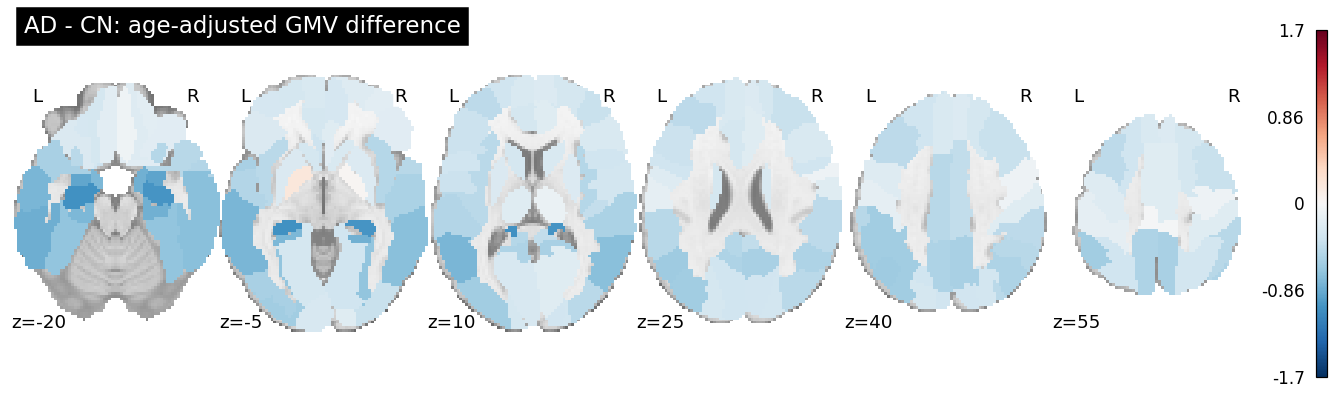

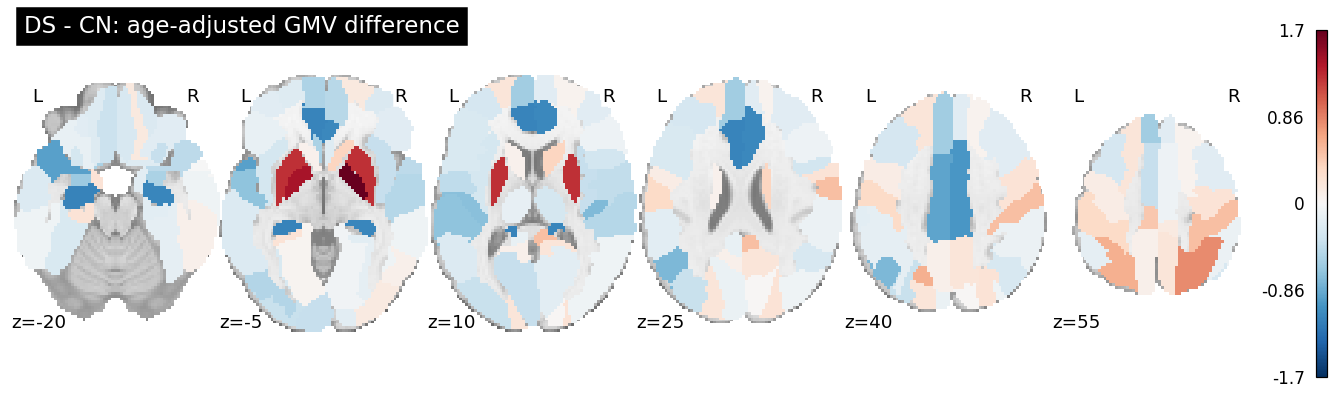

In [22]:
# Plotting cross-sectional GMV differences

atlas_img = nib.load(ROOT / "assets" / "AAL.nii.gz") #load the atlas
atlas_labels = pd.read_csv(ROOT / "assets" / "aal_labels.csv") # ROIs' labels/names
atlas_values = np.asarray(atlas_img.dataobj) # ROIs' indexes (voxes-level)
name_to_code = dict(zip(atlas_labels["name"], atlas_labels["code"])) # map ROIs' values to names, e.g., ("Region_A", 101) --> "Region_A": 101
# so, you can access ROIs like name_to_code["Region_A"]

limit = float(np.max(np.abs(effects["difference"]))) # this is just for the color scale
for contrast in ["AD - CN", "DS - CN"]: 

    # in this block, we're just mapping the values (GMV differences) to all voxels ROI by ROI
    values = effects.loc[effects["contrast"] == contrast].set_index("ROI")["difference"]
    volume = np.zeros(atlas_img.shape, dtype=np.float32)
    for roi in rois:
        volume[atlas_values == name_to_code[roi[2:]]] = values[roi]
    stat_img = nib.Nifti1Image(volume, atlas_img.affine)
    fig = plt.figure(figsize=(12, 3.5))
    view = plotting.plot_stat_map(stat_img, bg_img=ROOT / "assets" / "background.nii.gz",
                                  display_mode="z", cut_coords=[-20, -5, 10, 25, 40, 55],
                                  threshold=0, cmap="RdBu_r", symmetric_cbar=True, black_bg=False,
                                  vmin=-limit, vmax=limit, colorbar=True, figure=fig,
                                  title=contrast + ": age-adjusted GMV difference")
    plt.show()